# Exploración inicial — NHANES 2013–2014 (UCI 887)


Este notebook documenta la **descarga reproducible del dataset**, una exploración descriptiva inicial de **diabetes reportada (`DIQ010`)**, y los pasos para versionar los datos con **DVC**

**Pregunta del proyecto:** ¿qué patrones en indicadores metabólicos y características de los participantes se relacionan con haber reportado un diagnóstico de diabetes?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((x for x in candidates if (x / "requirements-eda.txt").exists() or (x / ".git").exists()), None)
if ROOT is None:
    raise RuntimeError("Abre el notebook desde el repositorio del proyecto en VS Code.")
DATA_PATH = ROOT / "data" / "raw" / "NHANES_age_prediction.csv"
OUT = ROOT / "reports" / "figures"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print("Raíz:", ROOT)
print("Archivo de datos:", DATA_PATH)

Raíz: /Users/alixgutierrez/Documents/Maestria MIAD/Ultimo semestre/Despliegue de soluciones/Proyecto/MIAD-DSA-Metabolic-Health-Explorer
Archivo de datos: /Users/alixgutierrez/Documents/Maestria MIAD/Ultimo semestre/Despliegue de soluciones/Proyecto/MIAD-DSA-Metabolic-Health-Explorer/data/raw/NHANES_age_prediction.csv


## 1. Carga y validación del dataset

Se consulta el **dataset 887** mediante `ucimlrepo` y se conserva una copia CSV sin modificar. Si el archivo ya existe, se reutiliza para no sobrescribir la versión que controla DVC. La descarga requiere conexión a internet en la primera ejecución.

In [2]:
if not DATA_PATH.exists():
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=887)
    raw = dataset.data.original
    if raw is None or raw.empty:
        raise RuntimeError("No fue posible recuperar los datos originales desde UCI 887")
    raw.to_csv(DATA_PATH, index=False)
    print("Datos descargados desde UCI")
else:
    print("Se utilizará el CSV local existente")

df = pd.read_csv(DATA_PATH)
required = {"SEQN", "age_group", "RIDAGEYR", "RIAGENDR", "PAQ605", "BMXBMI", "LBXGLU", "DIQ010", "LBXGLT", "LBXIN"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Columnas faltantes: {sorted(missing)}")
print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas")
if len(df) != 6287:
    print("Advertencia: el conteo difiere de las 6.287 observaciones declaradas en UCI; revisar versión")
display(df.head())

Datos descargados desde UCI
Dimensiones: 2,278 filas y 10 columnas
Advertencia: el conteo difiere de las 6.287 observaciones declaradas en UCI; revisar versión


,SEQN,age_group,RIDAGEYR,RIAGENDR,PAQ605,BMXBMI,LBXGLU,DIQ010,LBXGLT,LBXIN
0,73564.0,Adult,61.0,2.0,2.0,35.7,110.0,2.0,150.0,14.91
1,73568.0,Adult,26.0,2.0,2.0,20.3,89.0,2.0,80.0,3.85
2,73576.0,Adult,16.0,1.0,2.0,23.2,89.0,2.0,68.0,6.14
3,73577.0,Adult,32.0,1.0,2.0,28.9,104.0,2.0,84.0,16.15
4,73580.0,Adult,38.0,2.0,1.0,35.9,103.0,2.0,81.0,10.92


## 2. Estructura y calidad básica

Aquí verificamos tipos, faltantes y rangos, **sin concluir aún** que los datos estén limpios ni que sean representativos del país sin considerar el diseño muestral.

In [3]:
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(), "porcentaje_nulos": (df.isna().mean()*100).round(2)}))
display(df[["RIDAGEYR", "BMXBMI", "LBXGLU", "LBXGLT", "LBXIN"]].describe().T.round(2))

,tipo,nulos,porcentaje_nulos
SEQN,float64,0,0.0
age_group,object,0,0.0
RIDAGEYR,float64,0,0.0
RIAGENDR,float64,0,0.0
PAQ605,float64,0,0.0
BMXBMI,float64,0,0.0
LBXGLU,float64,0,0.0
DIQ010,float64,0,0.0
LBXGLT,float64,0,0.0
LBXIN,float64,0,0.0


,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,2278.0,41.80,20.16,12.00,24.00,41.00,58.00,80.00
BMXBMI,2278.0,27.96,7.25,14.50,22.80,26.80,31.20,70.10
LBXGLU,2278.0,99.55,17.89,63.00,91.00,97.00,104.00,405.00
LBXGLT,2278.0,114.98,47.06,40.00,87.00,105.00,130.00,604.00
LBXIN,2278.0,11.83,9.72,0.14,5.86,9.04,14.44,102.29


## 3. Diabetes reportada: codificación y distribución

`DIQ010` es una respuesta de encuesta acerca de si un profesional de salud ha indicado previamente que la persona tiene diabetes. En la codificación NHANES: **1 = Sí; 2 = No; 3 = Borderline/prediabetes; 7 = Rechazó; 9 = No sabe**. Conservamos el conteo de **todas** las respuestas y utilizamos solo 1 y 2 para la comparación binaria. Validar estos códigos con el [cuestionario oficial de NHANES](https://wwwn.cdc.gov/Nchs/Nhanes/2013-2014/DIQ_H.htm).

,codigo_DI Q010,participantes,respuesta
0,1.0,21,Sí
1,2.0,2199,No
2,3.0,58,Prediabetes / borderline


,participantes,porcentaje
diabetes_reportada,,
No,2199,99.05
Sí,21,0.95


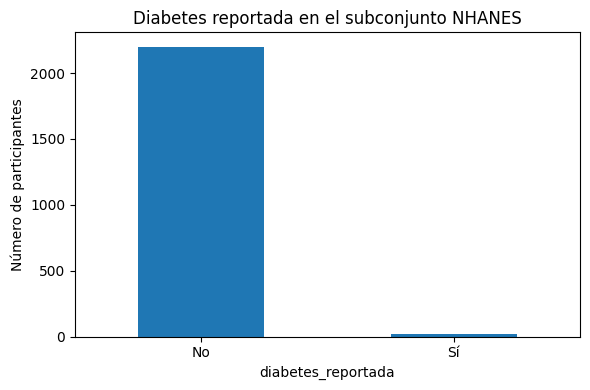

Participantes con Sí/No: 2,220; respuestas excluidas de esta comparación: 58


In [4]:
labels = {1:"Sí", 2:"No", 3:"Prediabetes / borderline", 7:"Rechazó", 9:"No sabe"}
raw_counts = df["DIQ010"].value_counts(dropna=False).sort_index()
all_responses = raw_counts.rename_axis("codigo_DI Q010").reset_index(name="participantes")
all_responses["respuesta"] = all_responses.iloc[:,0].map(labels).fillna("Faltante / otro")
display(all_responses)

valid = df[df["DIQ010"].isin([1,2])].copy()
valid["diabetes_reportada"] = valid["DIQ010"].map({1:"Sí",2:"No"})
counts = valid["diabetes_reportada"].value_counts().reindex(["No","Sí"],fill_value=0)
count_table = pd.DataFrame({"participantes":counts,"porcentaje": (counts/counts.sum()*100).round(2)})
display(count_table)
count_table.to_csv(OUT / "conteo_diabetes.csv", index_label="diabetes_reportada")
ax = counts.plot(kind="bar", rot=0, title="Diabetes reportada en el subconjunto NHANES", ylabel="Número de participantes", figsize=(6,4))
plt.tight_layout()
plt.savefig(OUT / "conteo_diabetes.png", dpi=160)
plt.show()
print(f"Participantes con Sí/No: {len(valid):,}; respuestas excluidas de esta comparación: {len(df)-len(valid):,}")

## 4. Comparación preliminar de indicadores metabólicos

Esta tabla responde inicialmente si **IMC, glucosa, insulina y edad** difieren entre quienes declaran **sí** y **no** a `DIQ010`.

RIDAGEYR                      BMXBMI                      \
                      count   mean median    std  count   mean median   std   
diabetes_reportada                                                            
No                     2199  41.26   40.0  20.07   2199  27.83   26.7  7.17   
Sí                       21  59.95   60.0  14.54     21  31.05   29.1  6.39   

                   LBXGLU                       LBXGLT                         \
                    count    mean median    std  count    mean median     std   
diabetes_reportada                                                              
No                   2199   98.63   97.0  14.25   2199  112.61  104.0   42.54   
Sí                     21  148.86  114.0  81.19     21  234.24  219.0  128.17   

                   LBXIN                       
                   count   mean median    std  
diabetes_reportada                             
No                  2199  11.66   8.96   9.46  
Sí                    21  14.97   9.58  16.75

/var/folders/gy/99__mgv95mb3txyj1r1stjc40000gn/T/ipykernel_78433/2441333056.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=["No","Sí"], showfliers=False)


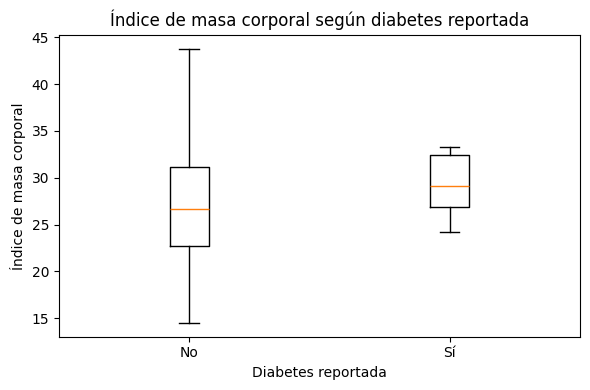

/var/folders/gy/99__mgv95mb3txyj1r1stjc40000gn/T/ipykernel_78433/2441333056.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=["No","Sí"], showfliers=False)


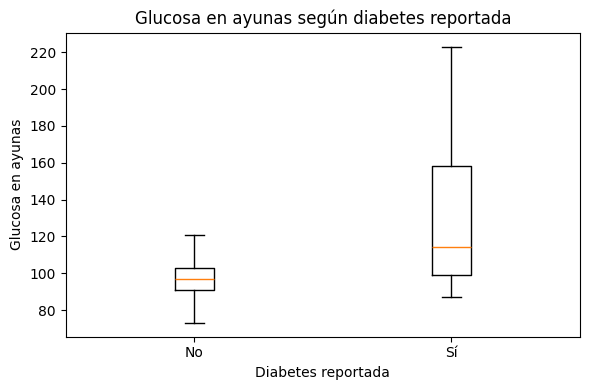

In [5]:
metrics = ["RIDAGEYR", "BMXBMI", "LBXGLU", "LBXGLT", "LBXIN"]
summary = valid.groupby("diabetes_reportada")[metrics].agg(["count","mean","median","std"])
display(summary.round(2))
summary.to_csv(OUT / "indicadores_por_diabetes.csv")

for var, label in [("BMXBMI","Índice de masa corporal"),("LBXGLU","Glucosa en ayunas")]:
    fig, ax = plt.subplots(figsize=(6,4))
    groups = [valid.loc[valid["diabetes_reportada"]==v,var].dropna() for v in ["No","Sí"]]
    ax.boxplot(groups, labels=["No","Sí"], showfliers=False)
    ax.set(xlabel="Diabetes reportada", ylabel=label, title=f"{label} según diabetes reportada")
    fig.tight_layout()
    fig.savefig(OUT / f"boxplot_{var}.png",dpi=160)
    plt.show()

## 5. Actividad física reportada

Exploramos el porcentaje de categorías originales de `PAQ605` por respuesta a diabetes. 

In [6]:
activity = pd.crosstab(valid["diabetes_reportada"], valid["PAQ605"], normalize="index", dropna=False).mul(100).round(1)
display(activity)
activity.to_csv(OUT / "actividad_por_diabetes.csv")

PAQ605,1.0,2.0,7.0
diabetes_reportada,,,
No,17.7,82.2,0.0
Sí,28.6,71.4,0.0


## 6. Hallazgos iniciales

